# E1 — Diagnóstico y necesidades Chilexpress
Datos sintéticos. Instrucciones: PDF E1 de tres páginas y enunciado general.
Se preservan los tres lotes y sus cortes. Ver INFORME_DESARROLLO.md para audiencias, preguntas, metodología, límites y decisiones. El módulo local contiene el procedimiento íntegro, comentado y reproducible; esta sesión lo ejecuta desde cero.
La recomendación es preliminar; no demuestra causalidad. Asistencia de IA declarada. No se simulan pruebas humanas.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'desarrollo'/'analisis_e1.py').exists())
sys.path.insert(0,str(ROOT/'desarrollo'))
from analisis_e1 import run
resumen = run()


{
  "entidades": 240000,
  "expuestos": 233657,
  "evaluados": 232957,
  "incumplimientos": 40100,
  "desconocidos": 700,
  "cumplimiento_pct": 82.78652283468622,
  "atraso_media_h": 46.51449939020697,
  "atraso_p90_h": 47.29561111111111,
  "costo_medio_clp": 4670.662373017535,
  "reclamos_pct": 7.635829034698212,
  "rho_peso_costo": 0.4614161928912634
}
           zona tipo_zona  ranking_tasa  ranking_equilibrado  turnos
 Zona docente 8     rural           1.0                    1       5
 Zona docente 4     rural           2.0                    2       5
Zona docente 12     rural           3.0                    3       0
Zona docente 24     rural           4.0                    4       0
Zona docente 16     rural           6.0                    5       0
Zona docente 20     rural           5.0                    6       0
 Zona docente 1    urbana           7.0                    7       0
 Zona docente 3    urbana           8.0                    8       0
 Zona docente 2    urb

In [2]:
import pandas as pd
from IPython.display import display, Image, Markdown
OUT = ROOT/'resultados'/'E1'
for nombre in ['inventario','lotes','matriz_reglas','perfil_calidad','ranking_turnos','cambio_sla','ranking_estandarizado','comparacion_metas','fichas_indicadores']:
    display(Markdown('### '+nombre))
    display(pd.read_csv(OUT/(nombre+'.csv')))


### inventario

,archivo,filas,columnas,clave,claves_distintas,granularidad,sha256,procedencia
0,datos/actualizacion/envios.csv,20100,14,envio_id,20000,envío al corte de su lote,2bce78f84e9b3d868d74ad1f49b694b6566b627bf986a2...,Paquete docente local; datos sintéticos
1,datos/ampliacion/envios.csv,100000,14,envio_id,100000,envío al corte de su lote,3b5ce20a3945808ca33ee19df0eefd7c678221ebcb32b4...,Paquete docente local; datos sintéticos
2,datos/base/envios.csv,120600,14,envio_id,120000,envío al corte de su lote,a61a4ef078bbea93d14de7ca238512ccd7992a96502927...,Paquete docente local; datos sintéticos
3,datos/complementarios/eventos_envio.csv,200000,4,evento_id,200000,"evento logístico, dos por envío nuevo",1ade7b4efb872a585b75ff518c62322b3f3e21af7ea915...,Paquete docente local; datos sintéticos
4,datos/complementarios/metas_2025_ancho.csv,24,16,destino_id/indicador,24,destino/indicador con meses en columnas,fd2353a7e3ca696b5e72d7ea8983b58a0c8a2eff6be276...,Paquete docente local; datos sintéticos
5,datos/complementarios/sla_historial.csv,96,5,destino_id/servicio/vigente_desde,96,versión temporal destino/servicio,116fc56b6fb3e2f91d586b17474d39c53f3ed2ed2488b5...,Paquete docente local; datos sintéticos
6,datos/dimensiones/destinos.csv,24,4,destino_id,24,destino,10ed7531914d4c6a4986c63322068db68b982b15574d7c...,Paquete docente local; datos sintéticos
7,datos/dimensiones/metas_ancho.csv,24,11,destino_id/indicador,24,destino/indicador con meses en columnas,04e996c1e21dbafdbad0e7b04a8e894a763de2cfff16d6...,Paquete docente local; datos sintéticos
8,datos/dimensiones/sla.csv,48,3,destino_id/servicio,48,destino/servicio estático,1378c182e5fd0f499ecb87e38801a3354d7bfc88e475d0...,Paquete docente local; datos sintéticos


### lotes

,lote,filas_fisicas,entidades,copias_exactas,corte_UTC
0,base,120600,120000,600,2025-07-08
1,actualizacion,20100,20000,100,2025-08-08
2,ampliacion,100000,100000,0,2026-01-08


### matriz_reglas

...

,destino_id,tasa_estandarizada_pct,estratos
0,C-D00,17.640986,2
1,C-D01,17.350762,2
2,C-D02,17.395803,2
3,C-D03,33.240270,2
4,C-D04,16.646626,2
5,C-D05,17.084565,2
6,C-D06,17.280302,2
7,C-D07,33.792748,2
8,C-D08,11.112299,2
9,C-D09,11.114097,2


### comparacion_metas

,destino_id,mes,cumplimientos,denominador,cumplimiento_pct,indicador,unidad,sentido,meta,brecha_pp
0,C-D00,2025-01,769,834,92.206235,cumplimiento_pct,%,minimo,90,2.206235
1,C-D00,2025-02,693,764,90.706806,cumplimiento_pct,%,minimo,90,0.706806
2,C-D00,2025-03,774,846,91.489362,cumplimiento_pct,%,minimo,90,1.489362
3,C-D00,2025-04,702,783,89.655172,cumplimiento_pct,%,minimo,90,-0.344828
4,C-D00,2025-05,691,890,77.640449,cumplimiento_pct,%,minimo,90,-12.359551
...,...,...,...,...,...,...,...,...,...,...
283,C-D23,2025-08,602,838,71.837709,cumplimiento_pct,%,minimo,90,-18.162291
284,C-D23,2025-09,539,785,68.662420,cumplimiento_pct,%,minimo,90,-21.337580
285,C-D23,2025-10,547,807,67.781908,cumplimiento_pct,%,minimo,90,-22.218092
286,C-D23,2025-11,531,780,68.076923,cumplimiento_pct,%,minimo,90,-21.923077


### fichas_indicadores

,id,tipo,objetivo,formula,numerador,denominador,unidad,granularidad,fuente_columnas,poblacion,periodo_corte,tratamiento_nulos,umbral,responsable,accion
0,K1,KPI,Cumplimiento,100*cumplimientos/evaluados,cumplimientos,evaluados,%,zona/semana/servicio; mínimo 100 evaluados,"fecha,compromiso,entrega,estado,corte",K1–K4: promesas vencidas no canceladas con res...,2025; corte propio de cada lote,Excluir campo inválido del denominador y publi...,meta docente por destino/mes para K1; restante...,equipo operacional docente,Priorizar capacidad
1,K2,KPI,Volumen incumplido,sum(incumple),incumplimientos,no aplica: conteo,envíos,zona/semana/servicio; mínimo 100 evaluados,"estado,compromiso,entrega,corte",K1–K4: promesas vencidas no canceladas con res...,2025; corte propio de cada lote,Excluir campo inválido del denominador y publi...,meta docente por destino/mes para K1; restante...,equipo operacional docente,Dimensionar turnos
2,K3,KPI,Atraso promedio,sum(atraso_h)/evaluados,horas de atraso truncadas en 0,evaluados,h,zona/semana/servicio; mínimo 100 evaluados,"compromiso,entrega,estado,corte",K1–K4: promesas vencidas no canceladas con res...,2025; corte propio de cada lote,Excluir campo inválido del denominador y publi...,meta docente por destino/mes para K1; restante...,equipo operacional docente,Medir demora
3,K4,KPI,Atraso P90,"quantile(atraso_h,0.9)",distribución empírica,evaluados,h,zona/semana/servicio; mínimo 100 evaluados,"compromiso,entrega,estado,corte",K1–K4: promesas vencidas no canceladas con res...,2025; corte propio de cada lote,Excluir campo inválido del denominador y publi...,meta docente por destino/mes para K1; restante...,equipo operacional docente,Controlar cola
4,K5,KPI,Costo operacional medio,sum(costo válido)/n costo válido,costo operacional,no cancelados con costo válido,CLP/envío,zona/semana/servicio; mínimo 100 evaluados,"costo_operacion_clp,estado",K1–K4: promesas vencidas no canceladas con res...,2025; corte propio de cada lote,Excluir campo inválido del denominador y publi...,meta docente por destino/mes para K1; restante...,equipo operacional docente,Evaluar costo
5,K6,KPI,Tasa de reclamos,100*sum(reclamo=1)/n reclamo válido,reclamos,no cancelados con reclamo 0/1,%,zona/semana/servicio; mínimo 100 evaluados,"reclamo,estado",K1–K4: promesas vencidas no canceladas con res...,2025; corte propio de cada lote,Excluir campo inválido del denominador y publi...,meta docente por destino/mes para K1; restante...,equipo operacional docente,Vigilar experiencia
6,Q1,calidad,Completitud peso,100*filas_fallidas/filas_evaluadas,3850,entidades únicas,%,lote/ruralidad/servicio,peso_kg,entidades únicas,corte propio del lote,Conservar nulo; no imputar,0% defectos propuesto; latencia máxima 48h del...,responsable de datos docente,Conservar nulo; no imputar
7,Q2,calidad,Entrega obligatoria,100*filas_fallidas/filas_evaluadas,350,entregados,%,lote/ruralidad/servicio,entrega,entregados,corte propio del lote,Desconocido; contrastar eventos sin sobrescribir,0% defectos propuesto; latencia máxima 48h del...,responsable de datos docente,Desconocido; contrastar eventos sin sobrescribir
8,Q3,calidad,Consistencia temporal,100*filas_fallidas/filas_evaluadas,350,entregados con fecha,%,lote/ruralidad/servicio,entrega,entregados con fecha,corte propio del lote,Excluir del atraso; conservar evidencia,0% defectos propuesto; latencia máxima 48h del...,responsable de datos docente,Excluir del atraso; conservar evidencia
9,Q4,calidad,Integridad referencial,100*filas_fallidas/filas_evaluadas,580,entidades únicas,%,lote/ruralidad/servicio,destino_id,entidades únicas,corte propio del lote,Cuarentena para rankings,0% defectos propuesto; latencia máxima 48h del...,responsable de datos docente,Cuarentena para rankings


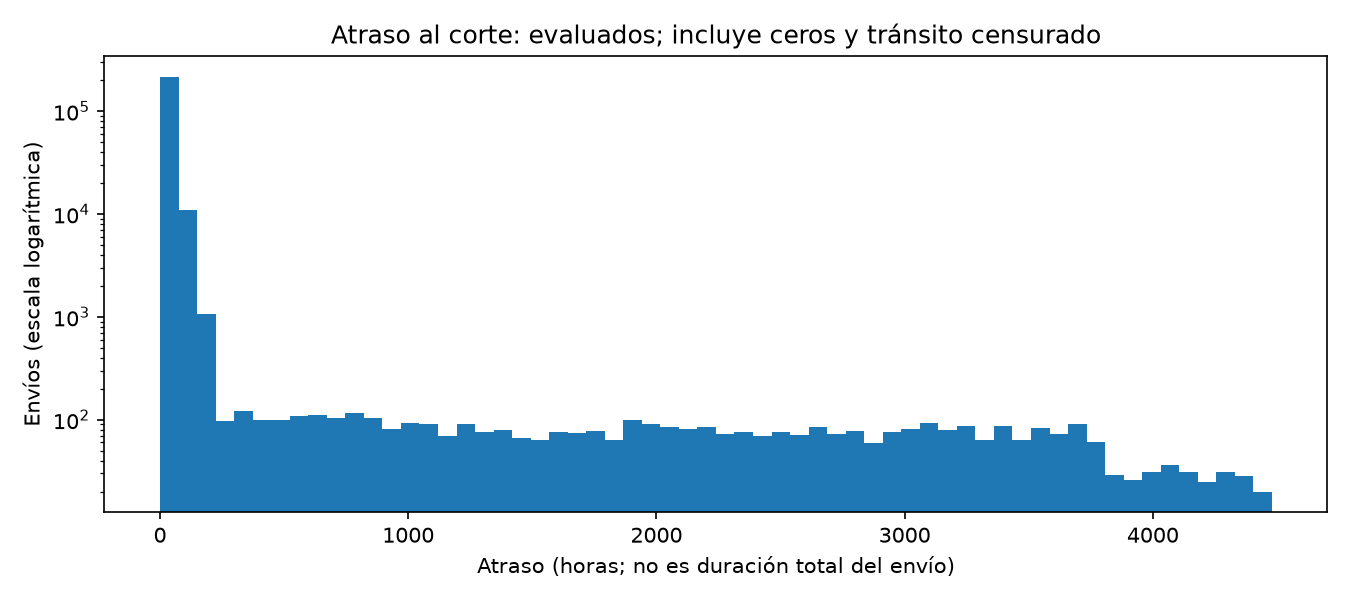

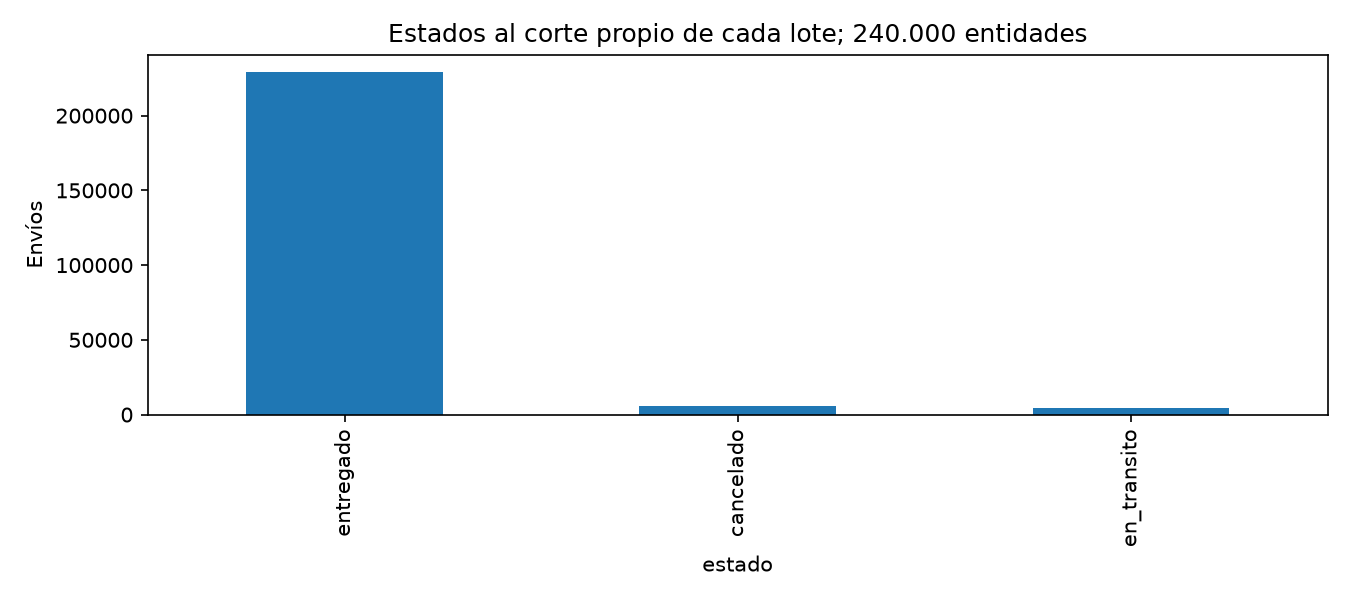

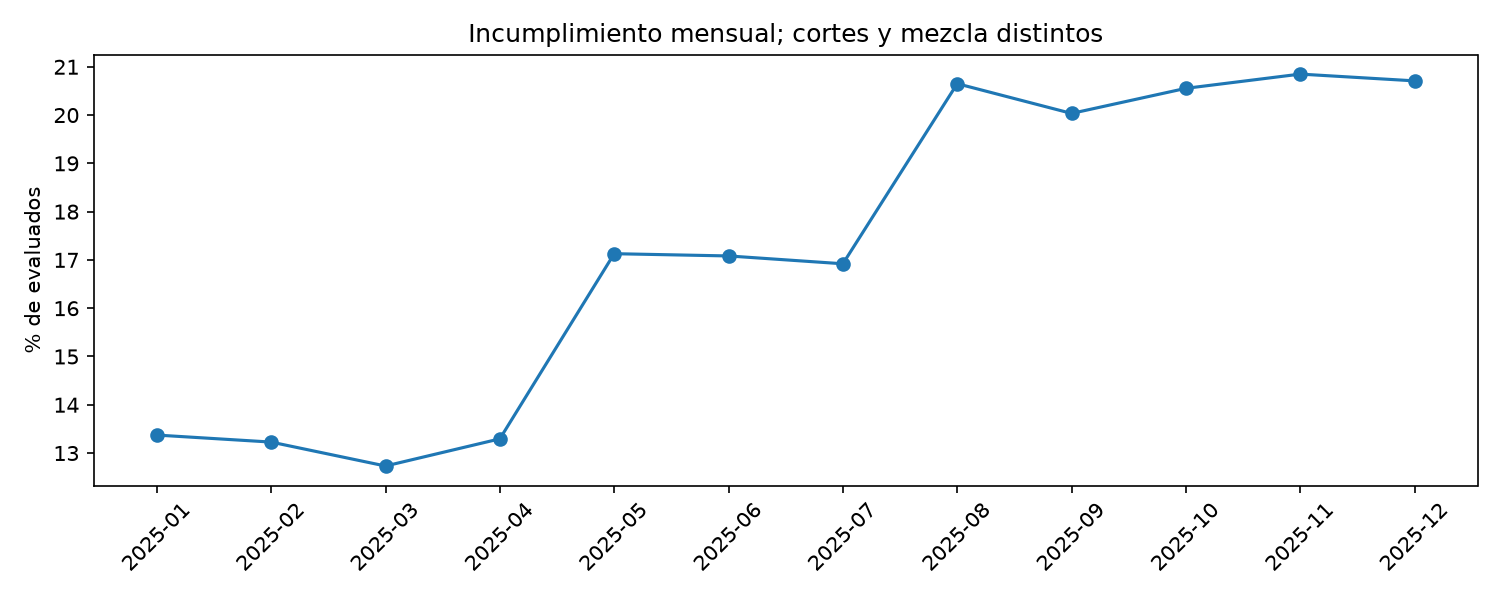

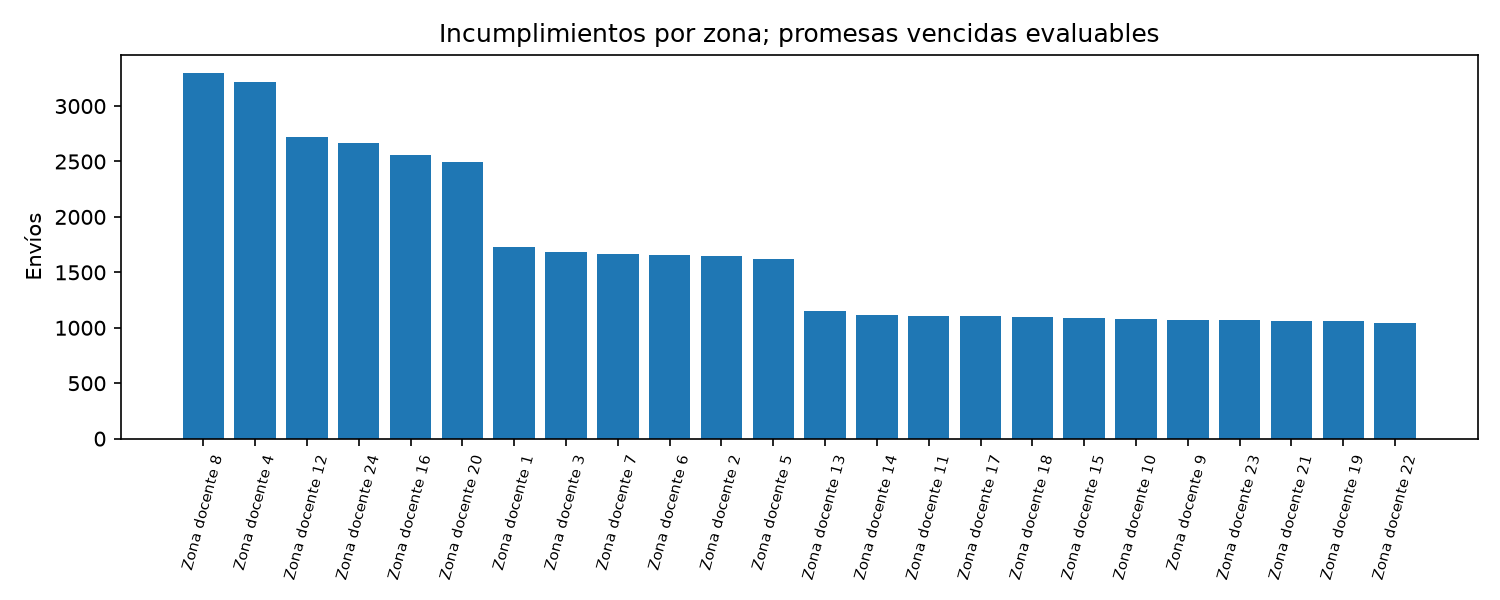

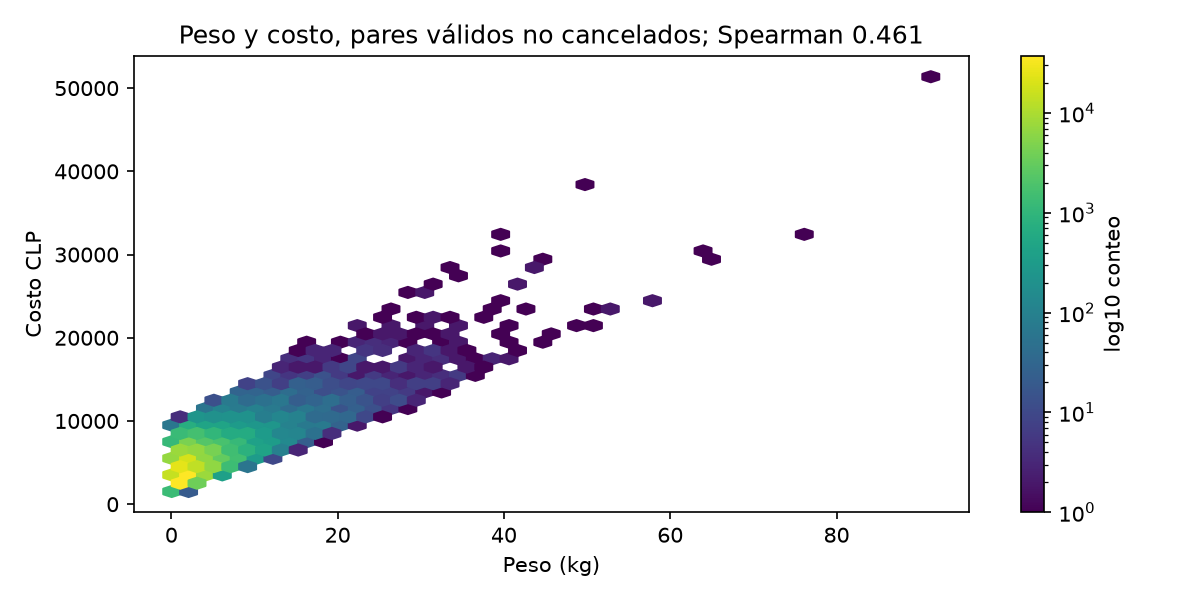

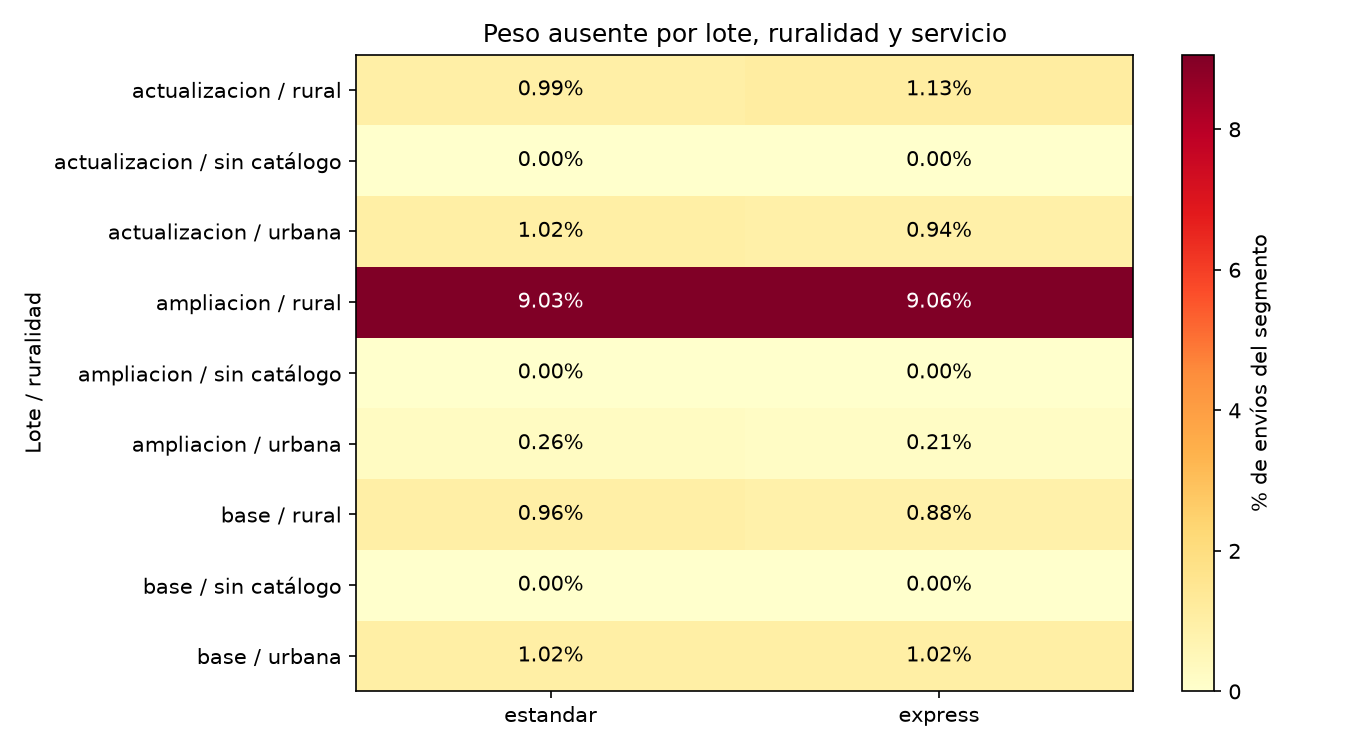

# INFORME DE DESARROLLO — E1 Chilexpress

## Introducción y alcance
Actividad académica del curso Visualización de Datos, profesor Viktor Tapia, Universidad de Santiago de Chile. Se leyó íntegramente Chilexpress_E1_Diagnostico.docx.pdf (3 páginas), el DOCX general, README, notebook inicial, diccionario, metadatos, plantillas y trazabilidad. El caso utiliza datos totalmente sintéticos. Se desarrolla E1 (RA1, IL1.1 e IL1.2), que no exige dashboard terminado ni predicción. E2–E4 se mencionan como contexto; faltan sus cuatro Word y la carpeta entregas. No se inventaron sus rúbricas.

## Objetivos y audiencia
Objetivo general: recomendar una distribución verificable de diez turnos semanales entre dos zonas para un piloto, equilibrando incumplimiento, volumen, costo y ruralidad.
Objetivos específicos: inventariar y verificar fuentes; separar filas y entidades; normalizar formatos; diagnosticar calidad; explorar seis perspectivas; definir seis KPI y seis métricas de calidad; documentar límites y limpieza.
Audiencia ejecutiva: coordinación docente que asigna capacidad y presupuesto. Audiencia operacional: supervisores docentes de zona que programan turnos y monitorean atrasos.

1. ¿Qué zonas, semanas y servicios concentran más incumplimientos y mayor tasa con al menos 100 evaluados? Cambia la selección de zonas y semanas del piloto.
2. ¿Dónde el P90 del atraso es elevado aun con media moderada, dentro del mismo servicio y ruralidad? Cambia la prioridad de seguimiento de la cola.
3. ¿Cómo cambia la prioridad al incorporar costo, ruralidad y mezcla de servicios? Cambia la distribución de los diez turnos y exige revisar SLA desde octubre.

## Archivos y contratos
Los nueve CSV del manifiesto se verifican por SHA-256 y dimensiones (inventario.csv). Base: 120.600 filas, enero–junio, corte UTC 08-07-2025; actualización: 20.100 filas, julio, corte 08-08-2025; ampliación: 100.000 filas, agosto–diciembre, corte 08-01-2026. Hay 240.700 filas físicas, 240.000 entidades y 700 copias exactas. La exposición es una población analítica de promesas vencidas, no filas ni eventos.
destinos aporta zona, región y ruralidad con unión N:1. sla_historial se une por destino, servicio y fecha dentro de [desde,hasta); nunca se aplica el SLA estático a todo el año. eventos_envio contiene 200.000 eventos de 100.000 envíos: se pivotea antes de unir 1:1. Los eventos no se suman como envíos. metas_2025_ancho se transforma a 288 filas tidy; sustituye analíticamente metas_ancho, sin concatenar versiones. Los catálogos estáticos se conservan e inventarían. Los eventos previos a agosto son ausencia de cobertura, no cero actividad.
diccionario_revisado.csv conserva las definiciones originales y agrega escalas, unidades y contratos. Se corrige peso de object a numérico y fecha a despacho UTC. Identificadores y categorías son nominales; instantes son de intervalo; pesos, distancias, costos y conteos son de razón. Entrega vacía es estructural en cancelado/en_transito y defecto en entregado. Cero en costos e intentos puede ser válido para cancelados.

## Herramientas y entorno
Python 3.14.3 en .venv; pandas, NumPy, Matplotlib, seaborn, Plotly, Streamlit y JupyterLab según requirements original, más pypdf, nbclient e ipykernel. Las versiones efectivamente usadas están en resultados/E1/versiones.json y desarrollo/requirements-lock.txt. Se usa pandas para análisis y Matplotlib para las seis figuras y el PDF; no se necesita una aplicación web para E1.

## Procedimiento y metodología
1. Lectura de las instrucciones antes del desarrollo; identificación de productos y rúbrica (audiencia 25, EDA 30, calidad 30, reproducibilidad 15 puntos).
2. Verificación de hashes y dimensiones antes y después del procesamiento. Lectura de CSV como texto para conservar formatos y claves.
3. Deduplicación exacta dentro de cada lote; validación de claves únicas globales. Los snapshots conservan su corte.
4. Normalización explícita ISO/fechas dd/mm a UTC y coma decimal sin miles a punto. bitacora_normalizacion.csv registra cada celda normalizada; no se recuperan valores dañados por conjetura.
5. Uniones con validación de cardinalidad; control de vigencias y cobertura; pivot de eventos y melt de metas.
6. Diagnóstico por lote/ruralidad/servicio antes de imputación. Las fechas inconsistentes o entregados sin entrega quedan como desconocidos para cumplimiento si la promesa está vencida. No se borran del total ni de la exposición.
7. Exposición: no cancelados con fecha y compromiso válidos y compromiso <= corte. Evaluados: exposición con entrega válida o en_transito. Incumplidos: entrega posterior a compromiso o tránsito vencido. Promesas aún no vencidas y cancelados se separan. Cumplimiento: cumplidos/evaluados; cada tabla publica numeradores, denominadores y desconocidos. Los límites de sensibilidad asignan todos los desconocidos primero a incumplidos y después a cumplidos.
8. Atraso=max(0,entrega-compromiso) en entregados válidos y max(0,corte-compromiso) en tránsito vencido; promedio y P90 incluyen ceros de todos los evaluados. No se confunde atraso condicional de incumplidos con atraso de la población evaluada.
9. Seis análisis y gráficos: distribución del atraso; categorías de estado; evolución mensual; comparación de zonas; relación peso/costo mediante Spearman sobre pares válidos; faltantes por segmento. zona_semana_servicio.csv ofrece el detalle semanal exigido y marca el mínimo propuesto de 100 evaluados.
10. comparacion_mismo_servicio_ruralidad.csv compara estratos; ranking_estandarizado.csv usa pesos comunes de servicio dentro de cada ruralidad para reducir efecto de mezcla. cambio_sla.csv expone promesa y SLA por mes/servicio/ruralidad. No se atribuye causalmente el cambio de octubre al desempeño.

## Resultados verificados
Se obtuvieron 240,000 entidades; 233,657 promesas vencidas expuestas; 232,957 evaluados, 40,100 incumplimientos y 700 resultados desconocidos entre expuestos. Cumplimiento observado: 82.79%. Atraso promedio: 46.51 h; P90: 47.30 h. El P90 y la media describen aspectos distintos de la cola; ambos deben revisarse por segmento antes de priorizar. Costo medio no cancelado: 4670.66 CLP; reclamos: 7.64%. Spearman peso/costo: 0.461, asociación sin interpretación causal.
La mayor tasa segmentada de peso ausente es 9.06% (faltantes_segmento.csv). El peso ausente puede distorsionar análisis de composición, peso y costo; excluirlo no altera por sí mismo el conteo de cumplimiento, pero una exclusión completa de filas sí sesgaría ese KPI. Las fechas de entrega dañadas impactan directamente cumplimiento y atraso. No se eliminan extremos solo por ser grandes: distribuciones.csv permite revisar percentiles 90/99 y máximos; sin evidencia de dominio, un extremo positivo es candidato a revisión, no defecto confirmado.

## Recomendación y contraste de rankings
Ranking alternativo: tasa de incumplimiento descendente. Ranking equilibrado: 45% percentil de volumen incumplido + 30% percentil de tasa + 15% percentil inverso de costo medio + 10% indicador rural. Menor costo se premia como aproximación de eficiencia; no es costo marginal por turno y no permite estimar retorno. Se usan todos los meses del año como diagnóstico, con madurez desigual advertida. ranking_turnos.csv publica los dos rankings para todas las zonas. No comparar rural y urbano como si fueran estratos equivalentes.
Propuesta: Zona docente 8 (rural): 5 turnos; Zona docente 4 (rural): 5 turnos. Se eligen las dos primeras zonas del score; diez turnos se reparten proporcionalmente a sus incumplimientos por método de restos mayores. Los pesos son una decisión docente transparente que debe validarse con responsables, no una optimización demostrada. Los rankings se contrastan también con tasas estandarizadas y límites de desconocidos; la propuesta es preliminar y sensible a estas políticas.
Piloto propuesto: cuatro semanas de línea base y cuatro de intervención; registrar turnos efectivamente realizados y exposición por zona/semana/servicio/ruralidad. Comparar cambios con zonas de control equivalentes y, si es factible, asignación aleatoria entre zonas elegibles. Medir cumplimiento, volumen incumplido, atraso medio/P90, costo y reclamos con igual ventana de maduración; publicar diferencias, denominadores e incertidumbre. Éxito propuesto: mejora de cumplimiento sin deterioro de costo/reclamos, con umbrales acordados antes de iniciar. No se ejecutó un piloto ni pruebas con usuarios reales.

## Calidad y plan de limpieza
matriz_reglas.csv registra campo, severidad, denominador, evaluados, fallas, tratamiento y efecto en KPI. perfil_calidad.csv ofrece seis métricas por lote/segmento: peso faltante, entrega obligatoria ausente, inconsistencia temporal, integridad de destino, latencia fuera de 0–48 h y cobertura SLA. La duplicación se registra adicionalmente sobre filas físicas; no se oculta tras deduplicar.
Primero normalizar formatos y quitar solo copias exactas. Después investigar fechas dañadas contrastando eventos disponibles desde agosto, sin sustituir ultimo_control por entrega; registrar evidencia antes de cualquier reparación. Mantener cuarentena analítica por indicador en vez de eliminar filas completas. Revisar faltantes rurales, fechas, costos/pesos no positivos y dominios de estado/servicio. Los historiales no se cambian retroactivamente. Los umbrales de defecto cero son propuestas de contrato, no verdades del paquete.

## Visualizaciones y evidencias
01_distribucion.png: histograma en horas, muestra ceros y cola; el tránsito está censurado. 02_categorias.png: conteos nominales de estados por entidad. 03_temporal.png: tasa mensual sobre evaluados; no compara cohortes con madurez idéntica. 04_segmentos.png: cantidad incumplida por zona; debe consultarse junto a tasa y denominador de ranking_turnos.csv. 05_bivariado.png: densidad peso/costo en pares válidos; no prueba causa. 06_faltantes.png: porcentaje de peso ausente por segmento; evita ocultarlo en el promedio global. Todas representan 2025 con cortes específicos; los CSV asociados contienen población, unidad y denominador. El PDF sintetiza audiencia, decisión, hallazgos, límites y limpieza en cinco páginas.

## Problemas, límites y pendientes
- Los datos y metas son sintéticos; no describen resultados reales de Chilexpress.
- Las asociaciones y rankings no prueban que diez turnos reduzcan el atraso. Se necesita un piloto.
- El tránsito vencido tiene atraso acumulado al corte, censurado: no es tiempo final de entrega.
- Los defectos excluidos del denominador pueden sesgar el cumplimiento; se publican desconocidos y límites inferior/superior.
- Los cortes tienen distinta madurez y el SLA rural cambia desde octubre; una variación agregada no identifica deterioro.
- El score y el mínimo 100 son políticas analíticas propuestas, no requisitos ni pesos dados por el profesor.
- No está instalada la herramienta rg; se usó PowerShell para inspección.
- Faltan entregas/ y sus Word. E1 se resuelve con el PDF disponible; E2–E4 quedan fuera del alcance verificable.
- No se dispone de integrantes ni pruebas humanas: la revisión independiente por un compañero y cualquier prueba con usuarios quedan pendientes, sin registros ficticios.
- Se declara asistencia de IA en código, análisis y redacción; la ejecución y validaciones automáticas aportan evidencia, pero no sustituyen revisión académica humana.

## Reproducción
Desde la raíz en PowerShell:
```powershell
python -m venv .venv
.\.venv\Scripts\python -m pip install -r desarrollo/requirements-lock.txt
.\.venv\Scripts\python desarrollo/analisis_e1.py
.\.venv\Scripts\python desarrollo/ejecutar_notebook.py
.\.venv\Scripts\python desarrollo/validar_resultados.py
```
E1_diagnostico.ipynb en la raíz puede ejecutarse desde una sesión nueva con el intérprete de .venv. Detecta la raíz buscando el script. La ejecución regenera resultados/E1 y el informe sin modificar los originales. versiones.json identifica el entorno probado; validaciones.json recoge controles. Los hashes de los nueve datos se comprueban antes y después.

## Registro de modificaciones
Solo se agregaron .venv/, .jupyter_e1/, desarrollo/, resultados/, E1_diagnostico.ipynb e INFORME_DESARROLLO.md. Dentro de resultados/E1 se generan CSV analíticos, seis PNG, resumen/validaciones/versiones JSON y Diagnostico.pdf. Los archivos del paquete original y el PDF de instrucciones se conservaron. El notebook inicial no se completó ni sobrescribió: se creó el notebook E1 solicitado.

## Cumplimiento y conclusiones
Se implementaron los seis trabajos requeridos por E1, los seis análisis, inventario con hashes, diccionario revisado, seis KPI y seis métricas de calidad, matriz de reglas, perfil segmentado, contraste de rankings, asignación de diez turnos y plan de piloto. Los entregables están en la raíz y resultados/E1. La calidad no se trata como un paso aislado: afecta los denominadores y la interpretación de la recomendación. La asignación es una hipótesis operativa para validar mediante piloto; no demuestra una mejora causal.
Pendientes externos: revisión por compañero, identificación del equipo, ejecución real del piloto y documentos faltantes para futuras entregas. No se afirma una calificación ni el cumplimiento de rúbricas no disponibles.


## Hallazgos segmentados y controles adicionales
Faltantes de peso por ruralidad, ponderados por número de envíos: rural: 4.35%; urbana: 0.70%. Fuente: faltantes_segmento.csv, entidades de 2025; ruralidad desconocida fuera de esta comparación. Una diferencia de cobertura limita las comparaciones de peso/costo.

Los dos rankings coinciden en las dos primeras zonas: Zona docente 8 (rural): 5 turnos; Zona docente 4 (rural): 5 turnos. Sus diferencias en posiciones restantes se consultan en ranking_turnos.csv; la coincidencia no prueba robustez ante otros pesos o ventanas. Las zonas sin catálogo y segmentos con menos de 100 evaluados se excluyen de la asignación, conservándose en zonas_incluyendo_no_identificados.csv.

SLA rural observado: estándar 96 h hasta septiembre y 108 h desde octubre; express 48 h y 60 h, respectivamente. Urbano: estándar 72 h y express 24 h. La promesa puede cambiar sin que cambie la duración física de la entrega, por lo que comparar solo cumplimiento agregado es insuficiente (cambio_sla.csv).

Calidad sobre entidades únicas tras normalización de formatos:

|Regla|Campo|Fallas|Evaluados|Tratamiento|
|---|---|---:|---:|---|
|Q1|peso_kg|3850|240000|Conservar nulo; no imputar|
|Q2|entrega|350|229418|Desconocido; contrastar eventos sin sobrescribir|
|Q3|entrega|350|229068|Excluir del atraso; conservar evidencia|
|Q4|destino_id|580|240000|Cuarentena para rankings|
|Q5|cargado_en|37776|240000|Investigar latencia; no comparar con hoy|
|Q6|sla_horas_vigente|920|240000|No sustituir por SLA estático|
|DUP|envio_id|700|240700|Deduplicar las 14 columnas dentro de cada lote|
|FECHA|fecha|340|240000|Cuarentena temporal; no inventar día|
|PESO|peso_kg|960|240000|Excluir peso inválido de relaciones físicas; conservar envío|
|SERVICIO|servicio|1500|240000|Normalizar espacios y mayúsculas; registrar original|

Las variantes de servicio con espacios/mayúsculas se normalizan con trazabilidad; servicios_originales.csv conserva su distribución previa. Las fechas imposibles se convierten a NaT solo en la copia analítica, y se registran en bitacora_normalizacion.csv. Los envíos sin fecha válida no se clasifican automáticamente como promesas futuras: no_cancelados_no_expuestos incluye casos no determinables; revisar dominios.csv y nulos_campos_segmento.csv. evidencia_eventos.csv cuenta candidatos con evidencia de entrega para una eventual limpieza posterior, sin aplicar una reparación en E1.

Instalación: la resolución inicial de pip se demoró; preparar_entorno.py descargó wheels compatibles mediante la API JSON de PyPI, comprobó sus hashes y los instaló localmente. pip check verificó dependencias. Para reinstalar sin red, ejecutar `.\.venv\Scripts\python -m pip install --no-index --find-links desarrollo/wheels -r desarrollo/requirements-lock.txt` tras crear .venv. .jupyter_e1/ mantiene kernel y cachés dentro del proyecto porque el directorio personal de IPython no permite escritura en esta sesión. No se cambiaron configuraciones globales.

Verificación independiente: validar_resultados.py recalcula entidades, exposición, evaluados, incumplidos y desconocidos directamente con csv/datetime, sin pandas; exige coincidencia con resumen.json, verifica los hashes de las 21 fuentes y comprueba cinco páginas máximas del PDF y ejecución sin errores del notebook. Su evidencia se guarda en verificacion_independiente.json. El histograma usa escala logarítmica en el conteo para hacer visible la cola sin eliminar extremos.


In [3]:
for nombre in ['01_distribucion','02_categorias','03_temporal','04_segmentos','05_bivariado','06_faltantes']:
    display(Image(filename=str(OUT/(nombre+'.png'))))
display(Markdown((ROOT/'INFORME_DESARROLLO.md').read_text(encoding='utf-8')))
